PART 1: SVM WITH DIFFERENT KERNELS
linear kernel: Accuracy = 0.8722
linear kernel: Accuracy Train = 0.8667
poly kernel: Accuracy = 0.8778
poly kernel: Accuracy Train = 0.8500
rbf kernel: Accuracy = 0.9056
rbf kernel: Accuracy Train = 0.9262


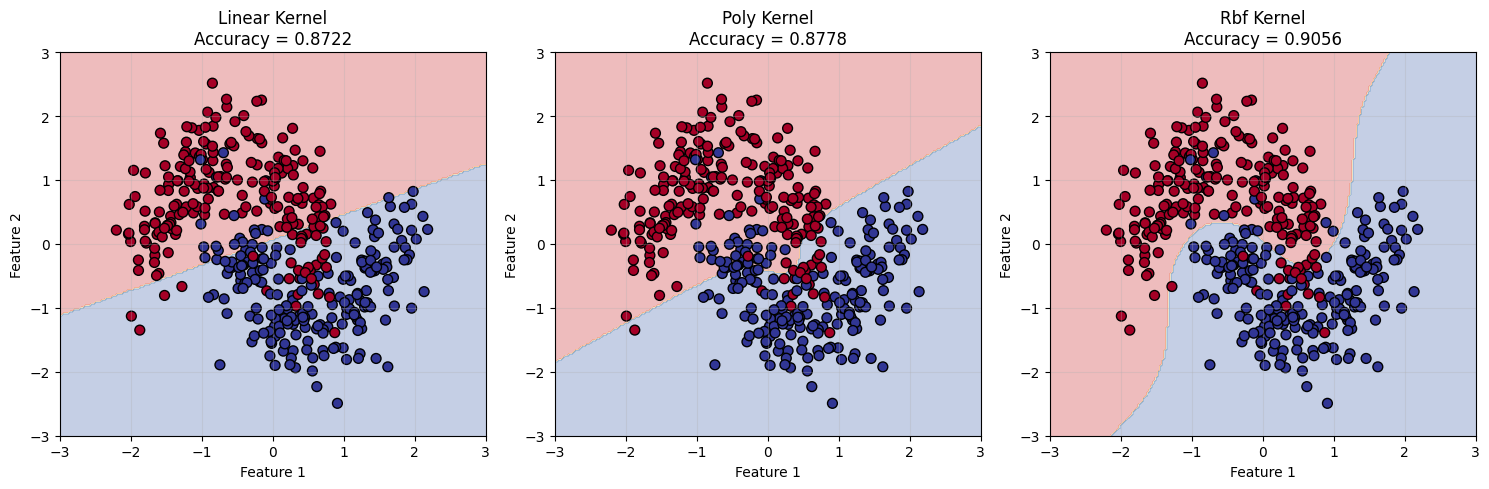


PART 2: SVM ON CIRCLES DATASET
linear kernel on Circles: Accuracy = 0.5389
linear kernel: Accuracy Train = 0.5524
poly kernel on Circles: Accuracy = 0.6111
poly kernel: Accuracy Train = 0.6262
rbf kernel on Circles: Accuracy = 0.9500
rbf kernel: Accuracy Train = 0.9357


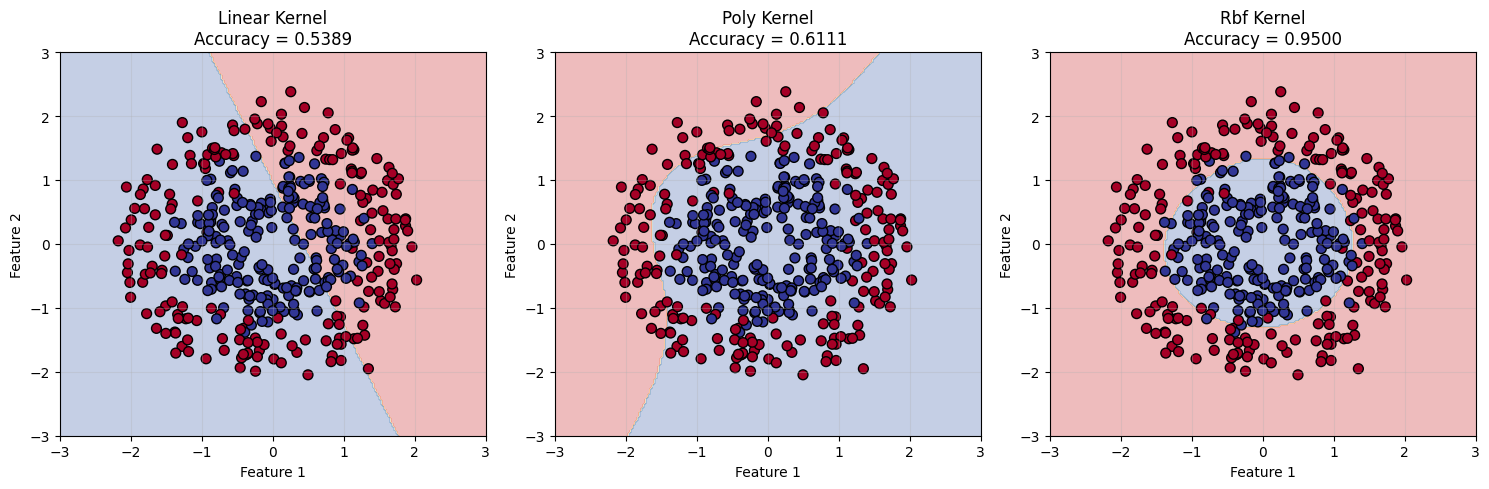


PART 3: MARGIN ANALYSIS


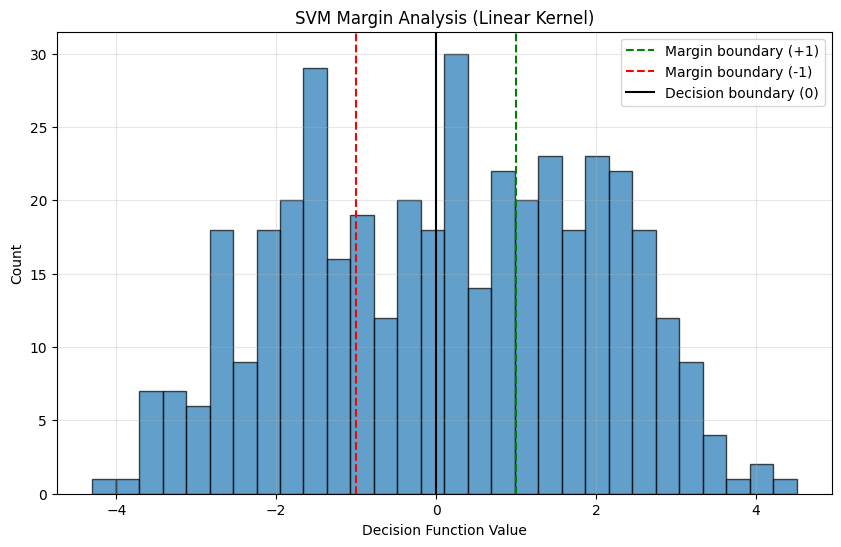


PART 4: C PARAMETER EFFECT

Effect of C on SVM (RBF kernel):
--------------------------------------------------


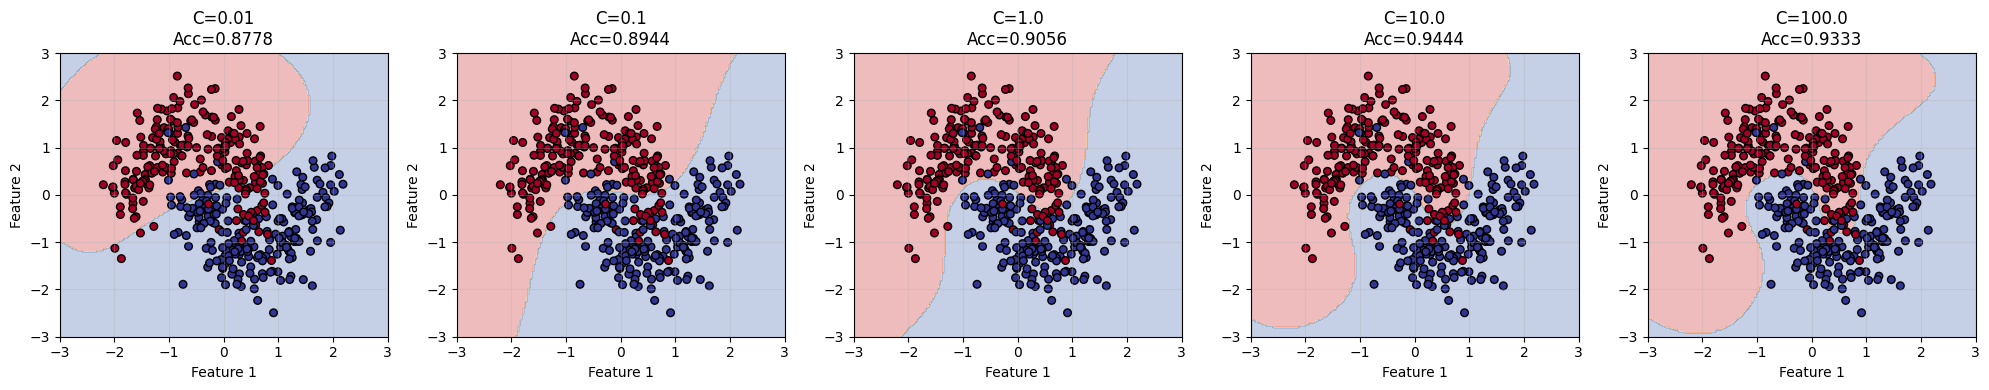

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

print("="*50)
print("PART 1: SVM WITH DIFFERENT KERNELS")
print("="*50)

# Generate Two Moons dataset
X_moons, y_moons = make_moons(n_samples=600, noise=0.25, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_moons, y_moons, test_size=0.3, random_state=42)

# Scale data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train SVM with different kernels
kernels = ['linear', 'poly', 'rbf']
svm_models = {}
accuracies = []

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, kernel in enumerate(kernels):
    svm = SVC(kernel=kernel, C=1.0, gamma='scale')
    svm.fit(X_train_scaled, y_train)
    svm_models[kernel] = svm
    
    y_pred = svm.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    
    y_pred_train = svm.predict(X_train_scaled)
    acc_train = accuracy_score(y_train, y_pred_train)
    
    print(f"{kernel} kernel: Accuracy = {acc:.4f}")
    print(f"{kernel} kernel: Accuracy Train = {acc_train:.4f}")
    
    # Plot decision boundary
    xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
    Z = svm.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    axes[idx].contourf(xx, yy, Z, alpha=0.3, cmap='RdYlBu')
    axes[idx].scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], 
                     c=y_train, cmap='RdYlBu', edgecolors='k', s=50)
    axes[idx].set_title(f'{kernel.capitalize()} Kernel\nAccuracy = {acc:.4f}')
    axes[idx].set_xlabel('Feature 1')
    axes[idx].set_ylabel('Feature 2')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('svm_kernels_moons.png', dpi=150)
plt.show()

print("\n" + "="*50)
print("PART 2: SVM ON CIRCLES DATASET")
print("="*50)

# Generate Circles dataset
X_circles, y_circles = make_circles(n_samples=600, noise=0.15, factor=0.5, random_state=42)
X_c_train, X_c_test, y_c_train, y_c_test = train_test_split(X_circles, y_circles, test_size=0.3, random_state=42)

# Scale
X_c_train_scaled = scaler.fit_transform(X_c_train)
X_c_test_scaled = scaler.transform(X_c_test)

# Train SVM with different kernels
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, kernel in enumerate(kernels):
    svm = SVC(kernel=kernel, C=1.0, gamma='scale')
    svm.fit(X_c_train_scaled, y_c_train)
    
    y_pred = svm.predict(X_c_test_scaled)
    acc = accuracy_score(y_c_test, y_pred)

    y_pred_train = svm.predict(X_c_train_scaled)
    acc_train = accuracy_score(y_c_train, y_pred_train)
    
    print(f"{kernel} kernel on Circles: Accuracy = {acc:.4f}")
    print(f"{kernel} kernel: Accuracy Train = {acc_train:.4f}")
    
    # Plot decision boundary
    xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
    Z = svm.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    axes[idx].contourf(xx, yy, Z, alpha=0.3, cmap='RdYlBu')
    axes[idx].scatter(X_c_train_scaled[:, 0], X_c_train_scaled[:, 1], 
                     c=y_c_train, cmap='RdYlBu', edgecolors='k', s=50)
    axes[idx].set_title(f'{kernel.capitalize()} Kernel\nAccuracy = {acc:.4f}')
    axes[idx].set_xlabel('Feature 1')
    axes[idx].set_ylabel('Feature 2')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('svm_kernels_circles.png', dpi=150)
plt.show()

print("\n" + "="*50)
print("PART 3: MARGIN ANALYSIS")
print("="*50)

# Train linear SVM on moons data
svm_linear = SVC(kernel='linear', C=1.0)
svm_linear.fit(X_train_scaled, y_train)

# Get decision function values
decisions = svm_linear.decision_function(X_train_scaled)

plt.figure(figsize=(10, 6))
plt.hist(decisions, bins=30, edgecolor='black', alpha=0.7)
plt.axvline(x=1, color='green', linestyle='--', label='Margin boundary (+1)')
plt.axvline(x=-1, color='red', linestyle='--', label='Margin boundary (-1)')
plt.axvline(x=0, color='black', linestyle='-', label='Decision boundary (0)')
plt.xlabel('Decision Function Value')
plt.ylabel('Count')
plt.title('SVM Margin Analysis (Linear Kernel)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('svm_margins.png', dpi=150)
plt.show()

print("\n" + "="*50)
print("PART 4: C PARAMETER EFFECT")
print("="*50)

C_values = [0.01, 0.1, 1.0, 10.0, 100.0]

print("\nEffect of C on SVM (RBF kernel):")
print("-" * 50)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for idx, C in enumerate(C_values):
    svm = SVC(kernel='rbf', C=C, gamma='scale')
    svm.fit(X_train_scaled, y_train)
    
    y_pred = svm.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    
    # Plot decision boundary
    xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
    Z = svm.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    axes[idx].contourf(xx, yy, Z, alpha=0.3, cmap='RdYlBu')
    axes[idx].scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], 
                     c=y_train, cmap='RdYlBu', edgecolors='k', s=30)
    axes[idx].set_title(f'C={C}\nAcc={acc:.4f}')
    axes[idx].set_xlabel('Feature 1')
    axes[idx].set_ylabel('Feature 2')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('svm_c_parameter.png', dpi=150)
plt.show()